Praktikum 3 - SVM Data Overlapping (efek hyperparameter C).

Data make_blobs dengan cluster_std besar => kelas tumpang tindih. Margin lunak
(soft margin) dikendalikan C: C besar = margin sempit/strict, C kecil = margin
lebar. Jumlah support vector dan akurasi dibandingkan.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("svm_overlap.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js11-klasifikasi-2\praktikum-3


In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC

OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(exist_ok=True)

In [3]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    P = model.decision_function(np.vstack([X.ravel(), Y.ravel()]).T).reshape(X.shape)
    ax.contour(X, Y, P, colors="k", levels=[-1, 0, 1], alpha=0.5,
               linestyles=["--", "-", "--"])
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
                   s=300, lw=1, facecolors="none", edgecolors="k")
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

[data] X=(100, 2) kelas=[50 50]


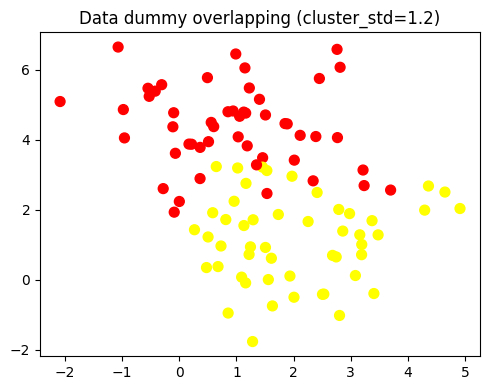

In [4]:
# --- Langkah 2: data overlapping ------------------------------------------
X, y = make_blobs(n_samples=100, centers=2, random_state=0, cluster_std=1.2)
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap="autumn")
ax.set_title("Data dummy overlapping (cluster_std=1.2)")
fig.tight_layout()
fig.savefig(OUT / "01_data_overlap.png", dpi=110)
print(f"[data] X={X.shape} kelas={np.bincount(y)}")

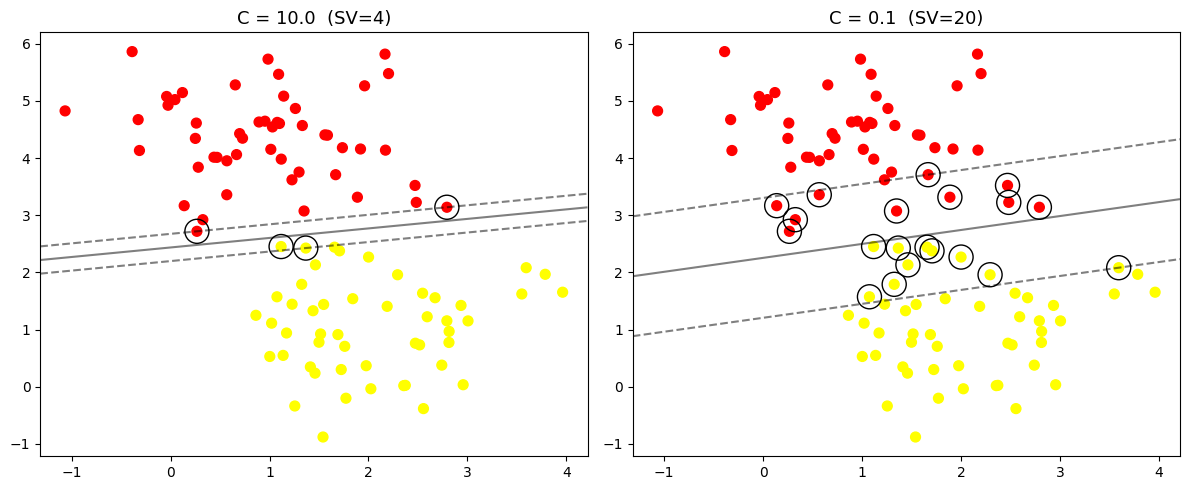

In [5]:
# --- Langkah 3: pengaruh C ------------------------------------------------
X, y = make_blobs(n_samples=100, centers=2, random_state=0, cluster_std=0.8)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel="linear", C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap="autumn")
    plot_svc_decision_function(model, axi)
    axi.set_title(f"C = {C:.1f}  (SV={len(model.support_vectors_)})", size=13)
fig.tight_layout()
fig.savefig(OUT / "02_pengaruh_C.png", dpi=110)

In [6]:
# tabel pengaruh C terhadap margin & support vector
print(f"{'C':>9} | {'akurasi latih':>13} | {'#SV':>4} | {'margin 2/|w|':>13}")
print("-" * 58)
for C in [0.01, 0.1, 1.0, 10.0, 100.0, 1e4]:
    m = SVC(kernel="linear", C=C).fit(X, y)
    w = m.coef_[0]
    margin = 2 / np.linalg.norm(w)  # lebar margin = 2/||w||
    print(f"{C:>9} | {accuracy_score(y, m.predict(X)):>13.4f} | "
          f"{len(m.support_vectors_):>4} | {margin:>10.4f}")
print("[catatan] C kecil -> margin lebar & banyak SV; C besar -> margin sempit, "
      "cenderung overfit. C optimal dicari lewat cross-validation (lihat praktikum 4).")
print("[selesai] praktikum 3")

        C | akurasi latih |  #SV |  margin 2/|w|
----------------------------------------------------------
     0.01 |        0.9900 |   52 |     3.5802
      0.1 |        1.0000 |   20 |     2.0380
      1.0 |        1.0000 |    9 |     0.8740
     10.0 |        1.0000 |    4 |     0.4702
    100.0 |        1.0000 |    3 |     0.4030
  10000.0 |        1.0000 |    3 |     0.4030
[catatan] C kecil -> margin lebar & banyak SV; C besar -> margin sempit, cenderung overfit. C optimal dicari lewat cross-validation (lihat praktikum 4).
[selesai] praktikum 3
